# Banking Stock Performance Analysis

## Research Question

How do the historical returns, volatility and risk-adjusted performance
of Barclays, HSBC and JPMorgan Chase compare over a one-year period?

## Project Overview

This project explores historical stock market data for three major banks
using Python.

The analysis examines:
- Share-price movements over time
- Daily percentage returns
- Volatility using standard deviation
- Total returns
- Risk-adjusted performance using the Sharpe ratio

## Tools and Libraries

- Python
- pandas
- yfinance
- Matplotlib

## Project Context

This is a guided learning project undertaken as part of developing
practical data science skills.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Collection

Historical stock market data was collected for Barclays, HSBC and JPMorgan using the Python library yfinance. The dataset covers approximately one year and includes daily opening, closing, highest and lowest prices, alongside trading volume. This provides the observations needed to compare the banks' financial performance.

In [2]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [3]:
import yfinance as yf

In [4]:
barclays = yf.download("BARC.L", period="1y", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


## 2. Data Exploration

Following data collection, an initial exploratory analysis was conducted using pandas to examine the structure and characteristics of the datasets. The .head() method was used to inspect the first observations, while .info() provided information about the variables, data types and completeness of the data. Descriptive statistics were generated using .describe() to examine measures such as the mean, standard deviation, minimum and maximum. This initial exploration helped establish an understanding of the datasets before conducting further financial analysis.

In [5]:
barclays.head().round(2)

Price,Close,High,Low,Open,Volume
Ticker,BARC.L,BARC.L,BARC.L,BARC.L,BARC.L
Date,,,,,
2025-10-16,379.16,383.09,375.11,379.31,23611230
2025-10-17,357.72,365.37,353.47,360.22,77116129
2025-10-20,361.72,363.85,357.52,361.12,34215853
2025-10-21,364.17,367.82,363.87,364.67,29867197
2025-10-22,381.91,384.51,371.13,372.42,114371754


In [6]:
barclays.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 253 entries, 2025-10-16 to 2026-10-16
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Close, BARC.L)   253 non-null    float64
 1   (High, BARC.L)    253 non-null    float64
 2   (Low, BARC.L)     253 non-null    float64
 3   (Open, BARC.L)    253 non-null    float64
 4   (Volume, BARC.L)  253 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.9 KB


In [7]:
barclays.describe().round(2)

Price,Close,High,Low,Open,Volume
Ticker,BARC.L,BARC.L,BARC.L,BARC.L,BARC.L
count,253.00,253.00,253.00,253.00,2.530000e+02
mean,457.09,463.27,451.23,457.11,4.731214e+07
std,41.24,41.38,41.08,41.35,2.583635e+07
min,357.72,363.85,353.47,360.22,4.908878e+06
25%,429.05,432.05,421.35,428.15,3.012622e+07
50%,458.05,466.50,454.60,461.10,3.966229e+07
75%,487.85,495.60,482.35,487.40,5.954967e+07
max,530.34,538.24,528.73,531.04,2.196452e+08


## 3. Share Price Analysis

The historical share-price performance of Barclays was visualised using Matplotlib. Adjusted daily closing prices were plotted over the one-year observation period to examine how the bank's share price changed over time. This visualisation provided an initial understanding of longer-term trends and short-term fluctuations. Adjusted closing prices were used to account for corporate actions such as dividends and stock splits, allowing a more consistent comparison of historical performance.

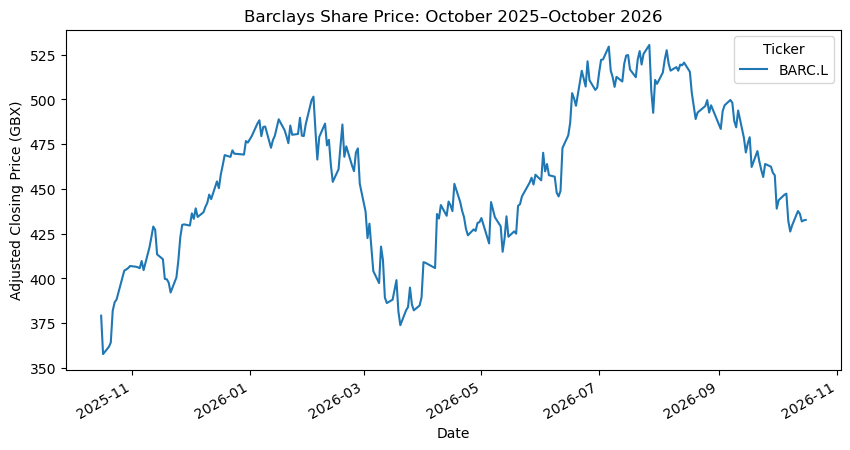

In [8]:
barclays["Close"].plot(
    figsize=(10, 5),
    title="Barclays Share Price: October 2025–October 2026"
)

plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (GBX)")
plt.show()

## 4. Daily Returns and Volatility

Daily percentage returns were calculated using the pandas .pct_change() method to measure the relative change in adjusted closing prices between consecutive trading days. These returns were visualised to examine fluctuations in daily performance. Volatility was measured using the standard deviation of daily returns, with monthly volatility calculated using the .resample() and .std() methods. This analysis helped distinguish between overall share-price growth and the variability of returns over time.

In [9]:
barclays.columns = barclays.columns.get_level_values(0)

In [10]:
barclays["Daily_Return"] = barclays["Close"].pct_change() * 100

In [11]:
barclays[["Close", "Daily_Return"]].head().round(2)

Price,Close,Daily_Return
Date,,
2025-10-16,379.16,NaN
2025-10-17,357.72,-5.66
2025-10-20,361.72,1.12
2025-10-21,364.17,0.68
2025-10-22,381.91,4.87


In [12]:
barclays["Daily_Return"].describe()

count    252.000000
mean       0.071537
std        1.963078
min       -5.655908
25%       -0.997589
50%        0.099052
75%        1.222231
max        7.442098
Name: Daily_Return, dtype: float64

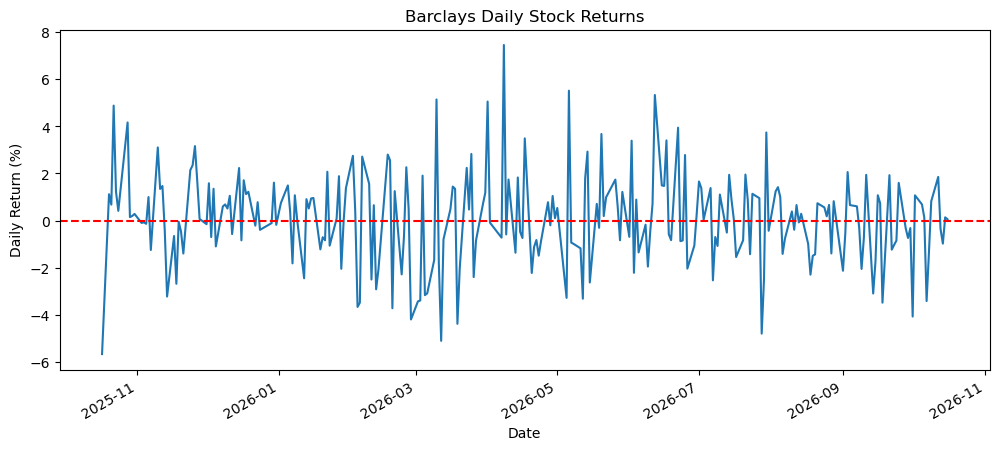

In [13]:
barclays["Daily_Return"].plot(
    figsize=(12, 5),
    title="Barclays Daily Stock Returns"
)

plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.axhline(y=0, color="red", linestyle="--")
plt.show()

In [14]:
monthly_volatility = barclays["Daily_Return"].resample("ME").std()

monthly_volatility.round(4)

Date
2025-10-31    2.8092
2025-11-30    1.7403
2025-12-31    0.9583
2026-01-31    1.2973
2026-02-28    2.5227
2026-03-31    2.6260
2026-04-30    2.3905
2026-05-31    2.2680
2026-06-30    2.1182
2026-07-31    1.8547
2026-08-31    1.0782
2026-09-30    1.5757
2026-10-31    1.7687
Freq: ME, Name: Daily_Return, dtype: float64

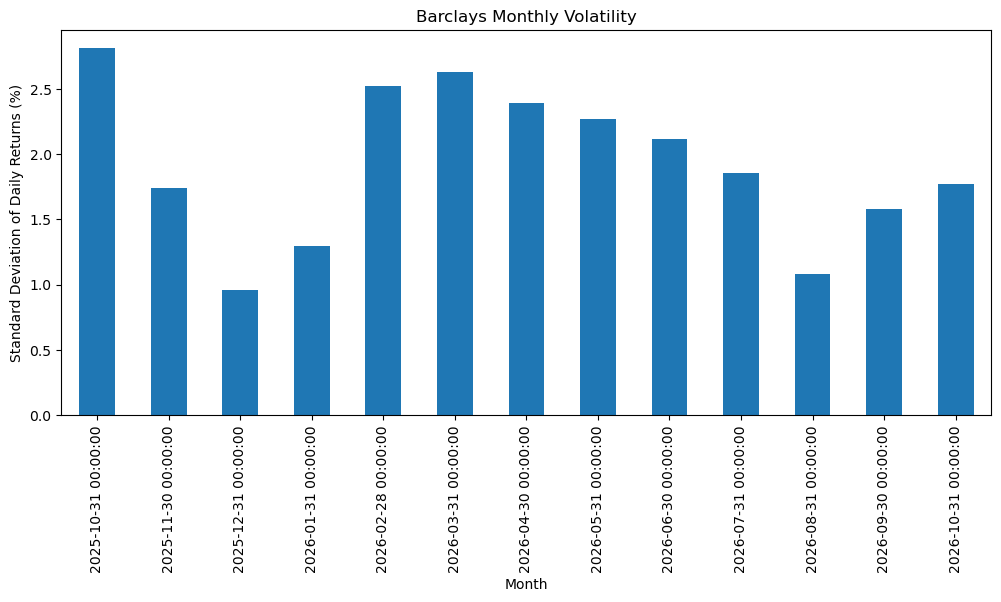

In [15]:
monthly_volatility.plot(
    kind="bar",
    figsize=(12, 5),
    title="Barclays Monthly Volatility"
)

plt.xlabel("Month")
plt.ylabel("Standard Deviation of Daily Returns (%)")
plt.show()

In [16]:
hsbc = yf.download("HSBA.L", period="1y", auto_adjust=True)

jpmorgan = yf.download("JPM", period="1y", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [17]:
hsbc.head()

Price,Close,High,Low,Open,Volume
Ticker,HSBA.L,HSBA.L,HSBA.L,HSBA.L,HSBA.L
Date,,,,,
2025-10-16,988.670166,991.918754,982.972692,983.472474,19988801
2025-10-17,963.880859,978.574482,958.869062,973.576656,34438548
2025-10-20,969.378540,987.570643,963.481141,987.570643,28094856
2025-10-21,984.571960,991.069136,982.272972,989.769713,20782243
2025-10-22,990.669250,996.209871,986.371131,988.370262,34911896


In [18]:
jpmorgan.head()

Price,Close,High,Low,Open,Volume
Ticker,JPM,JPM,JPM,JPM,JPM
Date,,,,,
2025-10-17,291.937347,293.889735,288.640852,293.507120,10153500
2025-10-20,296.646637,297.951522,292.526017,292.859589,6894900
2025-10-21,291.476257,298.304735,291.387962,295.959911,7372700
2025-10-22,288.552551,292.427925,285.050032,292.143396,8054100
2025-10-23,288.974426,290.769834,286.982786,288.817446,5438800


In [19]:
hsbc.columns = hsbc.columns.get_level_values(0)
jpmorgan.columns = jpmorgan.columns.get_level_values(0)

In [20]:
hsbc["Daily_Return"] = hsbc["Close"].pct_change() * 100
jpmorgan["Daily_Return"] = jpmorgan["Close"].pct_change() * 100

## 5. Comparative Performance Analysis

The daily returns of Barclays, HSBC and JPMorgan were combined into a single pandas DataFrame to facilitate comparison. Descriptive statistics were calculated to examine average daily returns and volatility across the three banks. Total returns were also calculated to assess overall performance during the observation period. Finally, the Sharpe ratio was used to compare risk-adjusted returns, using an assumed risk-free rate of zero for this introductory analysis.

In [21]:
comparison = pd.DataFrame({
    "Barclays": barclays["Daily_Return"],
    "HSBC": hsbc["Daily_Return"],
    "JPMorgan": jpmorgan["Daily_Return"]
})

comparison.agg(["mean", "std"]).round(2)

,Barclays,HSBC,JPMorgan
mean,0.07,0.16,0.07
std,1.96,1.70,1.40


In [22]:
bank_stats = comparison.agg(["mean", "std"]).T.round(3)

bank_stats

,mean,std
Barclays,0.072,1.963
HSBC,0.160,1.700
JPMorgan,0.070,1.396


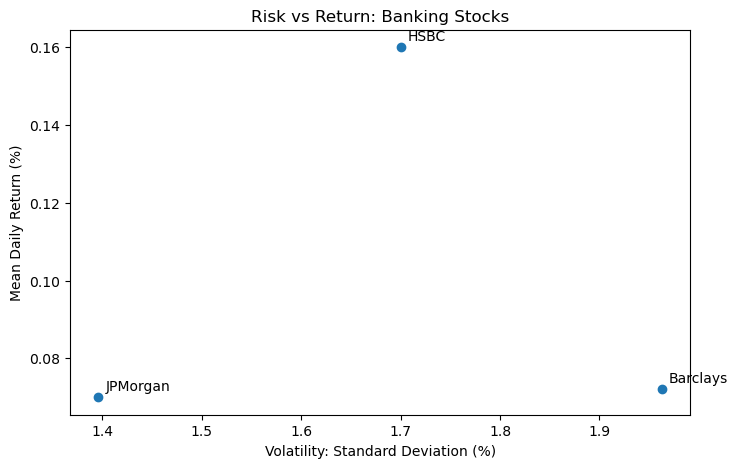

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(bank_stats["std"], bank_stats["mean"])

plt.xlabel("Volatility: Standard Deviation (%)")
plt.ylabel("Mean Daily Return (%)")
plt.title("Risk vs Return: Banking Stocks")
for bank in bank_stats.index:
    plt.annotate(
        bank,
        (bank_stats.loc[bank, "std"], bank_stats.loc[bank, "mean"]),
        xytext=(5, 5),
        textcoords="offset points"
    )
plt.show()

In [24]:
barclays_total_return = (
    barclays["Close"].iloc[-1] / barclays["Close"].iloc[0] - 1
) * 100

print(f"Barclays total return: {barclays_total_return:.2f}%")

Barclays total return: 14.11%


In [25]:
hsbc_total_return = (
    hsbc["Close"].iloc[-1] / hsbc["Close"].iloc[0] - 1
) * 100
print(f"HSBCs total return: {hsbc_total_return:.2f}%")

HSBCs total return: 44.44%


In [26]:
jpmorgan_total_return = (
    jpmorgan["Close"].iloc[-1] / jpmorgan["Close"].iloc[0] - 1
) * 100
print(f"JPMorgans total return: {jpmorgan_total_return:.2f}%")

JPMorgans total return: 16.37%


In [27]:
bank_stats

,mean,std
Barclays,0.072,1.963
HSBC,0.160,1.700
JPMorgan,0.070,1.396


In [28]:
risk_free_rate = 0

In [29]:
risk_free_rate = 0

bank_stats["sharpe_ratio"] = (
    bank_stats["mean"] - risk_free_rate
) / bank_stats["std"]

bank_stats.round(2)

,mean,std,sharpe_ratio
Barclays,0.07,1.96,0.04
HSBC,0.16,1.70,0.09
JPMorgan,0.07,1.40,0.05


## 6. Normalised Share Price Comparison

To compare share-price performance across banks trading at different prices and in different currencies, adjusted closing prices were normalised to a starting value of 100. This allowed relative price movements to be compared without relying on absolute share prices. Missing observations arising from differences in trading calendars were identified and excluded from the comparison visualisation. The resulting chart illustrated how each bank's share price changed relative to its initial value.

In [30]:
normalised = pd.DataFrame({
    "Barclays": barclays["Close"] / barclays["Close"].iloc[0] * 100,
    "HSBC": hsbc["Close"] / hsbc["Close"].iloc[0] * 100,
    "JPMorgan": jpmorgan["Close"] / jpmorgan["Close"].iloc[0] * 100
})

In [31]:
normalised.head().round(2)

,Barclays,HSBC,JPMorgan
Date,,,
2025-10-16,100.00,100.00,NaN
2025-10-17,94.34,97.49,100.00
2025-10-20,95.40,98.05,101.61
2025-10-21,96.04,99.59,99.84
2025-10-22,100.73,100.20,98.84


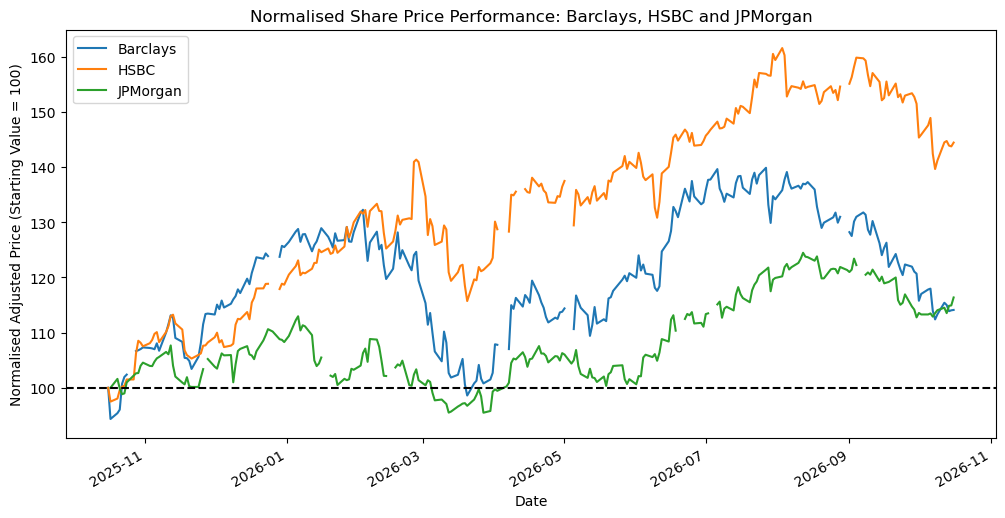

In [32]:
normalised.plot(figsize=(12, 6))

plt.title("Normalised Share Price Performance: Barclays, HSBC and JPMorgan")
plt.xlabel("Date")
plt.ylabel("Normalised Adjusted Price (Starting Value = 100)")
plt.axhline(y=100, color="black", linestyle="--")

plt.show()

In [33]:
normalised.isna().sum()

Barclays    5
HSBC        5
JPMorgan    7
dtype: int64

In [34]:
normalised[normalised.isna().any(axis=1)]

,Barclays,HSBC,JPMorgan
Date,,,
2025-10-16,100.000000,100.000000,NaN
2025-10-27,NaN,101.506417,102.214682
2025-11-27,113.368496,107.681081,NaN
2025-12-26,NaN,NaN,110.199627
2026-01-19,127.356625,125.253846,NaN
2026-02-16,121.568880,126.507577,NaN
2026-04-06,NaN,NaN,100.249221
2026-04-13,114.713280,NaN,106.434841
2026-05-04,NaN,NaN,104.388805


In [35]:
normalised_clean = normalised.dropna()

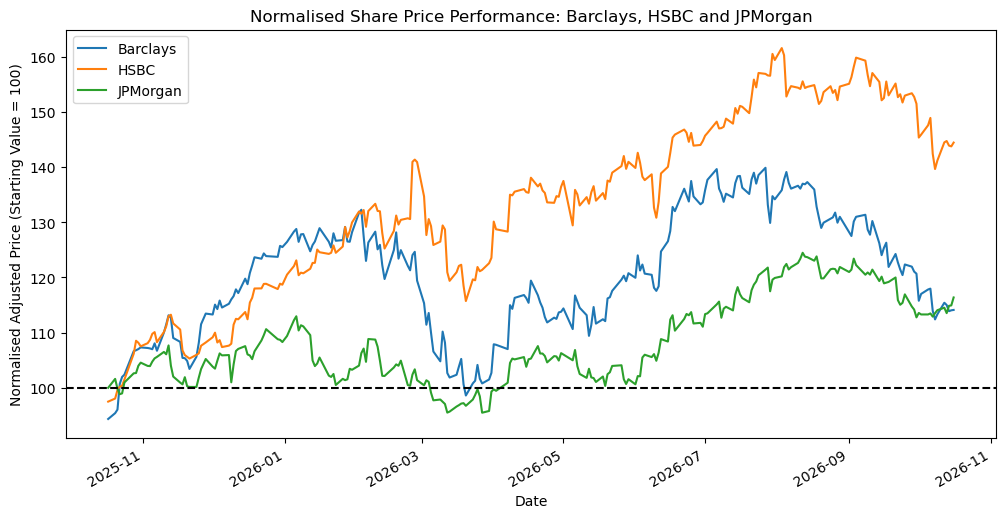

In [36]:
normalised_clean.plot(figsize=(12, 6))

plt.title("Normalised Share Price Performance: Barclays, HSBC and JPMorgan")
plt.xlabel("Date")
plt.ylabel("Normalised Adjusted Price (Starting Value = 100)")
plt.axhline(y=100, color="black", linestyle="--")

plt.show()

## 7. Findings and Discussion

The analysis identified differences in the historical performance and volatility of Barclays, HSBC and JPMorgan Chase over the one-year observation period.
Total Returns: HSBC achieved the highest total return at 44.40%, compared with 15.69% for JPMorgan and 14.11% for Barclays.
Volatility: Barclays exhibited the highest daily volatility, with a standard deviation of 1.96%, followed by HSBC at 1.70% and JPMorgan at 1.40%. This indicates that Barclays experienced greater variability in its daily percentage returns.
Risk-Adjusted Performance: HSBC demonstrated the strongest risk-adjusted performance according to the annualised Sharpe ratio calculated in this analysis, using an assumed risk-free rate of zero.
Overall, HSBC achieved the highest historical returns and strongest risk-adjusted performance among the three banks during the observation period. However, these findings describe historical performance and should not be interpreted as predictions of future returns.

## 8. Limitations and Conclusions

This analysis was limited to three banking stocks over approximately one year. Consequently, the findings may not reflect longer-term performance or broader banking-sector trends.
Although normalisation enabled comparison of relative share-price movements, Barclays and HSBC trade in GBP-denominated pence (GBX), while JPMorgan trades in US dollars (USD). Exchange-rate movements were not incorporated into the analysis, meaning the returns are not directly comparable from the perspective of an investor using a single base currency.
Additionally, volatility was measured using the standard deviation of daily returns, which captures variability but does not distinguish between positive and negative price movements. The Sharpe ratio was calculated using an assumed risk-free rate of zero, simplifying the analysis.
Despite these limitations, the project demonstrates how Python can be used to collect, clean, analyse and visualise financial data to investigate differences in historical investment performance.